# two temperature model

Reference code from my mentor. Credit Ben Ofori Okai

<>:22: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:22: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
/var/folders/rf/s1m2r2bn7nx64szrkz747pb40000gn/T/ipykernel_89957/2372664980.py:22: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  data = pd.read_csv(file, sep="\ ", header=None)


400
800
800_low
TeL [0.025851   0.025851   0.025851   ... 0.20606711 0.20601743 0.2059679 ]
Te [0.025851   0.025851   0.025851   ... 0.28025864 0.28019997 0.28014143]


/var/folders/rf/s1m2r2bn7nx64szrkz747pb40000gn/T/ipykernel_89957/2372664980.py:22: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  data = pd.read_csv(file, sep="\ ", header=None)
/var/folders/rf/s1m2r2bn7nx64szrkz747pb40000gn/T/ipykernel_89957/2372664980.py:22: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  data = pd.read_csv(file, sep="\ ", header=None)


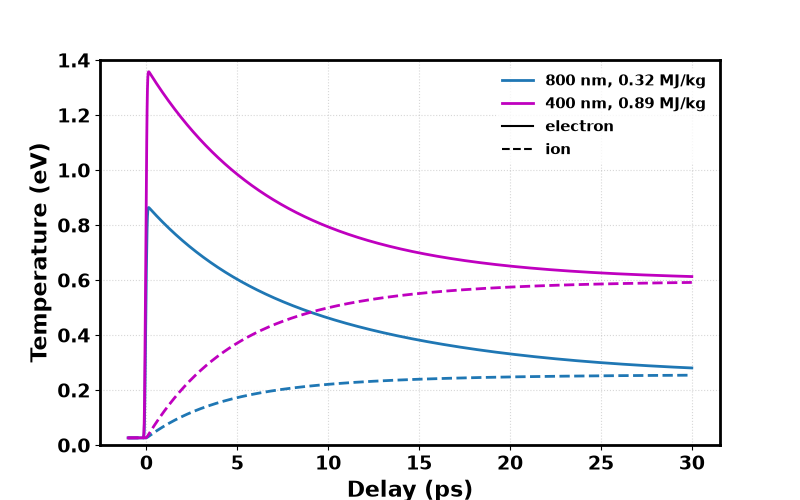

In [ ]:
import numpy as np
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import pandas as pd
from math import pi, sqrt
from pprint import pprint
%matplotlib widget

plt.rcParams.update({
    'axes.titlesize': 18,     # Title size
    'axes.labelsize': 16,     # X and Y label size
    'xtick.labelsize': 14,    # X tick size
    'ytick.labelsize': 14,    # Y tick size
    'legend.fontsize': 11     # Legend size
})
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['font.weight'] = 'bold'


plt.close('all')
def read(file):
    data = pd.read_csv(file, sep="\ ", header=None)
    return data

gData = read("G_Au.txt")
CeData = read("Ce_Au.txt")

G_inter = CubicSpline(gData.iloc[:,0], gData.iloc[:, 1])
Ce_inter = CubicSpline(CeData.iloc[:,0], CeData.iloc[:, 1])


MD = 19320 # kg m-3, mass density
TAU = 60e-15 # s, drive laser pulse is 60 fs
T0 = 0e-15 # s, delay for laser pulse to arrive
CI = 2.5e6 # J m-3 K-1

t0 = -1e-12 # s, begin at 0 ps
tn = 30e-12 # s, end at 30 ps
dt = 20e-15 # s, timestep is 15 fs
N = int((tn-t0)/dt) # number of steps
time = np.linspace(t0, tn, N+1)
Te = np.zeros(N+1)
Ti = np.zeros(N+1)
Te_400 = np.zeros(N+1)
Ti_400 = np.zeros(N+1)

TeL = np.zeros(N+1)
TiL = np.zeros(N+1)

# initialize temperatures to 300 K
Te[0] = 300.0
Ti[0] = 300.0
Te_400[0] = 300.0
Ti_400[0] = 300.0
TeL[0] = 300.0
TiL[0] = 300.0

data = {"400": [Te_400, Ti_400],
        "800": [Te, Ti],
        "800_low": [TeL, TiL]}

""" 800 nm """
U800 = (3.17e-1)*1e6 # J/kg, energy density

""" 400 nm """
U400 = 0.89e6 # J/kg, energy density 

""" 800 low """
U800_L = (2.24e-1)*1e6

for key in data:
    print(key)
    if key == "800":
        U = U800
    elif key == "400":
        U = U400
    elif key == "800_low":
        U = U800_L
    S0 = (U*MD)/(TAU*sqrt(pi)) # W m-3, max intensity
    S = lambda t : S0 * np.exp(-(t-T0)**2/TAU**2) # laser intensity as a function of time

    Te_, Ti_ = data[key]
    for i in range(N):
        G = G_inter((Te_[i]*1e-4))*1e17 # Te (1e4 K) and G (1e17 W m-3 K-1)
        Ce = Ce_inter((Te_[i]*1e-4))*1e5 # Te (1e4 K) and Ce (1e5 J m-3 K-1)
        S_t = S(time[i])

        A = dt/Ce
        Te_[i+1] = A*((-G * (Te_[i]-Ti_[i])) + S_t) + Te_[i]
        Ti_[i+1] = (dt*G/CI) * (Te_[i] - Ti_[i]) + Ti_[i]

time = time * 1e12 # ps
Te_eV = Te * 8.617e-5 # eV
Ti_eV = Ti * 8.617e-5 # eV
Te400_eV = Te_400 * 8.617e-5 # eV
Ti400_eV = Ti_400 * 8.617e-5 # eV
TeL_eV = TeL * 8.617e-5 # eV
TiL_eV = TiL * 8.617e-5 # eV
print("TeL", TeL_eV)
print("Te", Te_eV)
lw = 2
plt.figure(figsize=(8,5))
plt.plot(time, Te_eV, label=r"$0.32 \pm 0.06$ MJ/kg", lw=lw, color="tab:blue")
plt.plot(time, Ti_eV, lw=lw, color="tab:blue", linestyle="--")
plt.plot(time, Te400_eV, label="0.89 MJ/kg", lw=lw, color="m")
plt.plot(time, Ti400_eV, lw=lw, color="m", linestyle="--")

#plt.plot(time, TeL_eV, label="800 nm, 0.22 MJ/kg", lw=lw, color="tab:green", alpha=0.6, ls=":")
#plt.plot(time, TiL_eV, lw=lw, color="tab:green", linestyle="--")

plt.axhline(y=-2, color="black", label="electron")
plt.axhline(y=-2, color="black", label="ion", ls='--')
plt.xlabel("Delay (ps)", weight='bold')
plt.ylabel("Temperature (eV)", weight='bold')
plt.legend(edgecolor="None")
plt.ylim(0, 1.4)
plt.grid(axis="both", ls=":", alpha=0.5)
plt.show()

# plt.xlim(-2,10)

def graphS():
    x = np.linspace(-3e-15,2e-15, 500)
    y = S(x)
    plt.figure()
    plt.plot(x, y)
    plt.show()





## temp vs conductivity

[-2.0, -1.0, -0.0, 2.0, 5.0, 7.5, 10.0, 12.5, 15.0, 25.0, 50.0]
<class 'list'>
array([0.025851  , 0.025851  , 0.63419717, 0.74261114, 0.60245607,
       0.52148791, 0.46181536, 0.41656504, 0.38136628, 0.29948296,
       0.24726558])
[12845475.815421,
 14439835.866362244,
 7737502.982245647,
 6448612.76258447,
 5958020.85618009,
 5473082.318815806,
 5242825.073787406,
 5000475.709584896,
 4223838.308813534,
 4122942.9761048234,
 3708819.3475925266]


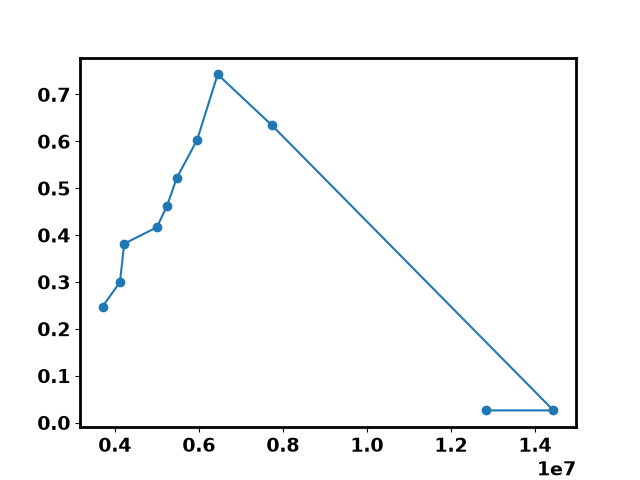

In [ ]:
import json
Te_inter = CubicSpline(time, Te_eV)

file_root = '/Users/yuewang/SLAC/goldthz/Au_data/code/'
def load(filename):
    with open(filename,"r") as file:
        raw = json.load(file)
    data = {float(key): value for key, value in raw.items()}
    return data

FFT400 = load(file_root + 'FFT method/400_nm_FFT.json')
FFT800_4 = load(file_root + 'FFT method/800_nm_FFT_4ps.json')
x = [float(k) for k in FFT400.keys()]
x.pop()
print(x)
print(type(x))
eTemp = Te_inter(x)
sigma400 = [s['mean'] for s in FFT400.values()]
sigma400.pop()
pprint(eTemp)
pprint(sigma400)

plt.figure()
plt.plot(sigma400, eTemp, "-o")

plt.show()

